# PRML Lab 6 — Dimensionality Reduction (PCA & LDA)
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)
SEED = 56
sns.set_theme(style='whitegrid')
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — Principal Component Analysis

### 1. Reading the raw files into a table, and EDA

In [2]:
COLS = ('family product_type steel carbon hardness temper_rolling condition formability strength non_ageing '
        'surface_finish surface_quality enamelability bc bf bt bw_me bl m chrom phos cbond marvi exptl ferro corr '
        'bbvc lustre jurofm s p shape thick width len oil bore packing class').split()
NUMERIC = ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']
raw = pd.concat([pd.read_csv(f'data/anneal.{f}', header=None, names=COLS, dtype=str) for f in ('data', 'test')],
                ignore_index=True)
raw.to_csv('data/anneal_combined.csv', index=False)
print('anneal.data + anneal.test =', raw.shape, '| exact duplicate rows:', raw.duplicated().sum())
raw.head()

anneal.data + anneal.test = (898, 39) | exact duplicate rows: 12


,family,product_type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non_ageing,...,s,p,shape,thick,width,len,oil,bore,packing,class
0,?,C,A,08,00,?,S,?,000,?,...,?,?,COIL,0.700,0610.0,0000,?,0000,?,3
1,?,C,R,00,00,?,S,2,000,?,...,?,?,COIL,3.200,0610.0,0000,?,0000,?,3
2,?,C,R,00,00,?,S,2,000,?,...,?,?,SHEET,0.700,1300.0,0762,?,0000,?,3
3,?,C,A,00,60,T,?,?,000,?,...,?,?,COIL,2.801,0385.1,0000,?,0000,?,3
4,?,C,A,00,60,T,?,?,000,?,...,?,?,SHEET,0.801,0255.0,0269,?,0000,?,3


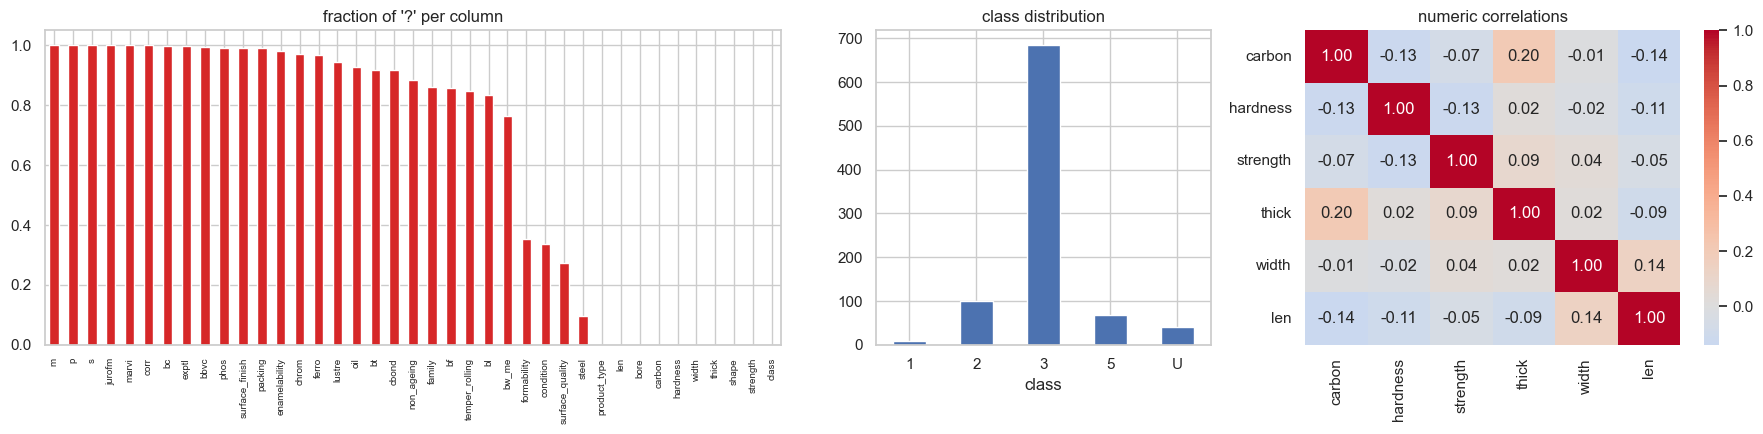

{'3': 684, '2': 99, '5': 67, 'U': 40, '1': 8}


,count,mean,std,min,25%,50%,75%,max
carbon,898.0,3.63,13.72,0.00,0.0,0.0,0.0,70.0
hardness,898.0,11.78,24.75,0.00,0.0,0.0,0.0,85.0
strength,898.0,30.67,114.96,0.00,0.0,0.0,0.0,700.0
thick,898.0,1.20,0.87,0.24,0.6,0.8,1.6,4.0
width,898.0,780.65,405.35,0.00,609.9,610.0,1250.0,1525.0
len,898.0,1263.09,1871.40,0.00,0.0,611.0,762.0,4880.0


In [3]:
qfrac = (raw == '?').mean().sort_values(ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={'width_ratios': [2.2, 1, 1.4]})
qfrac.plot.bar(ax=ax[0], color='tab:red'); ax[0].set_title("fraction of '?' per column"); ax[0].tick_params(axis='x', labelsize=7)
raw['class'].value_counts().sort_index().plot.bar(ax=ax[1], rot=0); ax[1].set_title('class distribution')
num = raw[NUMERIC].astype(float)
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[2]); ax[2].set_title('numeric correlations')
plt.tight_layout(); savefig('q1_eda'); plt.show()
print(raw['class'].value_counts().to_dict())
num.describe().T.round(2)

Observations:
- **Severe class imbalance:** class 3 is 76% of the data, class 1 has under 10 samples, and class 4 never occurs. Accuracy alone would flatter a model that ignores the small classes, so **macro-F1** and **balanced accuracy** are reported alongside it.
- **The `?` values are mostly "not applicable", not "missing":** the dataset notes say so, and for most binary process flags (`bc`, `bf`, `lustre`, …) the only values are a code or `?`. So `?` is kept as its own category (`NA`) instead of being imputed.
- **Seven columns have a single value** throughout (`product_type`, `m`, `marvi`, `corr`, `jurofm`, `s`, `p`) and carry no information.
- The numeric features are on very different scales (thickness ≈ 1 mm, length up to 4880 mm), so standardisation is essential before PCA.

### 2. Pre-processing and a 65:35 split

In [4]:
df = raw.drop_duplicates().reset_index(drop=True)
constant = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=constant)
CATEG = [c for c in df.columns if c not in NUMERIC + ['class']]
df[CATEG] = df[CATEG].replace('?', 'NA')
df[NUMERIC] = df[NUMERIC].astype(float)
X_df = pd.get_dummies(df[CATEG], dtype=float).join(df[NUMERIC])
y_all = df['class'].values
CLASSES = np.unique(y_all)
print(f'removed {len(raw) - len(df)} duplicate rows and {len(constant)} constant columns: {constant}')
print(f'{len(CATEG)} categorical → one-hot; final design matrix {X_df.shape}')

X_tr_df, X_te_df, y_tr, y_te = train_test_split(X_df, y_all, test_size=0.35, stratify=y_all, random_state=SEED)
mu, sd = X_tr_df.mean(), X_tr_df.std(ddof=0).replace(0, 1)      # statistics from the training split only
X_tr, X_te = ((X_tr_df - mu) / sd).values, ((X_te_df - mu) / sd).values
FEATURES = X_df.columns.tolist()
print('train', X_tr.shape, '| test', X_te.shape)
print('train classes', dict(zip(*np.unique(y_tr, return_counts=True))), '| test classes', dict(zip(*np.unique(y_te, return_counts=True))))

removed 12 duplicate rows and 7 constant columns: ['product_type', 'm', 'marvi', 'corr', 'jurofm', 's', 'p']
25 categorical → one-hot; final design matrix (886, 77)
train (575, 77) | test (311, 77)
train classes {'1': np.int64(5), '2': np.int64(63), '3': np.int64(438), '5': np.int64(44), 'U': np.int64(25)} | test classes {'1': np.int64(3), '2': np.int64(34), '3': np.int64(237), '5': np.int64(23), 'U': np.int64(14)}


### 3. Three classifiers with 5-fold cross-validation
- **Logistic regression** — a linear baseline. Its calibrated, regularised boundaries work well on one-hot data.
- **k-nearest neighbours (k = 5)** — depends entirely on distances, so it should be the model most affected by PCA.
- **Random forest** — handles mixed one-hot/numeric features and interactions naturally; a strong non-linear reference.

`class_weight='balanced'` is used where available, so the tiny classes are not ignored.

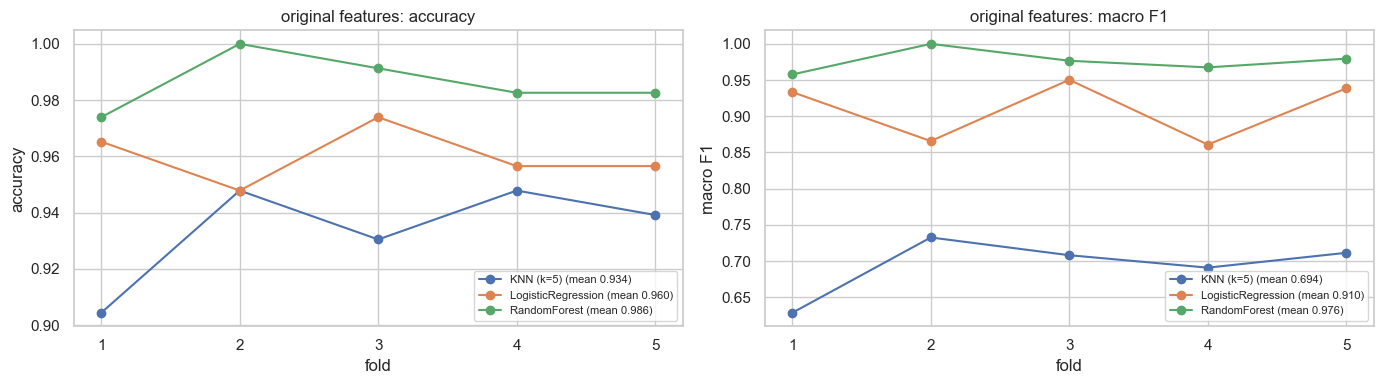

accuracy         macro F1        
                       mean     std     mean     std
model                                               
KNN (k=5)            0.9339  0.0180   0.6944  0.0396
LogisticRegression   0.9600  0.0099   0.9098  0.0429
RandomForest         0.9861  0.0099   0.9763  0.0158

In [5]:
MODELS = {
    'LogisticRegression': lambda: LogisticRegression(max_iter=3000, class_weight='balanced'),
    'KNN (k=5)': lambda: KNeighborsClassifier(5),
    'RandomForest': lambda: RandomForestClassifier(300, class_weight='balanced', random_state=SEED),
}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

def cv_scores(X, y):
    rows = []
    for name, make in MODELS.items():
        for fold, (tr, va) in enumerate(skf.split(X, y), 1):
            p = make().fit(X[tr], y[tr]).predict(X[va])
            rows.append({'model': name, 'fold': fold, 'accuracy': accuracy_score(y[va], p), 'macro F1': f1_score(y[va], p, average='macro')})
    return pd.DataFrame(rows)

def plot_cv(cv, title, name):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for a, metric in zip(ax, ['accuracy', 'macro F1']):
        for model, g in cv.groupby('model'):
            a.plot(g['fold'], g[metric], 'o-', label=f'{model} (mean {g[metric].mean():.3f})')
        a.set_xlabel('fold'); a.set_ylabel(metric); a.set_xticks(range(1, 6)); a.legend(fontsize=8); a.set_title(f'{title}: {metric}')
    plt.tight_layout(); savefig(name); plt.show()

cv_raw = cv_scores(X_tr, y_tr)
plot_cv(cv_raw, 'original features', 'q1_cv_original')
_agg = cv_raw.groupby('model')[['accuracy', 'macro F1']].agg(['mean', 'std']).round(4)
results['q1_cv_original'] = {m: {f'{a} {b}': v for (a, b), v in row.items()} for m, row in _agg.iterrows()}
cv_raw.groupby('model')[['accuracy', 'macro F1']].agg(['mean', 'std']).round(4)

### 4. PCA from scratch
**(a)** Centre and scale each feature with its own mean and standard deviation (already applied above, using the training statistics), then compute the covariance matrix $\Sigma = \frac{1}{n-1}X^\top X$ by hand.

**(b)** `Singular_Value_Decomp`. For a symmetric positive semi-definite matrix such as Σ, the SVD and the eigen-decomposition coincide: Σ = VΛVᵀ, and the singular values are the eigenvalues. I compute them with the **cyclic Jacobi eigenvalue algorithm**. Each step applies a plane rotation that sets the largest remaining off-diagonal entry pair to zero. Repeating until the off-diagonal mass is negligible leaves the eigenvalues on the diagonal, and the product of the rotations gives the eigenvectors. Principal components are the projections X·V.

In [6]:
def covariance_matrix(Xc):
    n = Xc.shape[0]
    return (Xc.T @ Xc) / (n - 1)

def Singular_Value_Decomp(S, tol=1e-12, max_sweeps=100):
    A = np.array(S, dtype=float)
    n = A.shape[0]
    V = np.eye(n)
    for sweep in range(max_sweeps):
        off = np.sqrt(np.sum(A ** 2) - np.sum(np.diag(A) ** 2))
        if off < tol:
            break
        for p in range(n - 1):
            for q in range(p + 1, n):
                if abs(A[p, q]) < 1e-15:
                    continue
                theta = (A[q, q] - A[p, p]) / (2 * A[p, q])
                t = np.sign(theta) / (abs(theta) + np.sqrt(theta ** 2 + 1)) if theta != 0 else 1.0
                c = 1 / np.sqrt(t ** 2 + 1); s = t * c
                Ap, Aq = A[:, p].copy(), A[:, q].copy()          # rotate columns p, q
                A[:, p], A[:, q] = c * Ap - s * Aq, s * Ap + c * Aq
                Ap, Aq = A[p, :].copy(), A[q, :].copy()          # rotate rows p, q
                A[p, :], A[q, :] = c * Ap - s * Aq, s * Ap + c * Aq
                Vp, Vq = V[:, p].copy(), V[:, q].copy()
                V[:, p], V[:, q] = c * Vp - s * Vq, s * Vp + c * Vq
    eigvals = np.diag(A).copy()
    order = np.argsort(eigvals)[::-1]
    return np.clip(eigvals[order], 0, None), V[:, order], sweep

class PCAScratch:
    def fit(self, X):
        self.cov_ = covariance_matrix(X)
        self.eigvals_, self.components_, self.sweeps_ = Singular_Value_Decomp(self.cov_)
        self.explained_ratio_ = self.eigvals_ / self.eigvals_.sum()
        return self
    def transform(self, X, k):
        return X @ self.components_[:, :k]

pca = PCAScratch().fit(X_tr)
ref = np.linalg.eigvalsh(pca.cov_)[::-1]
print(f'Jacobi converged in {pca.sweeps_} sweeps on a {pca.cov_.shape[0]}×{pca.cov_.shape[0]} covariance matrix')
print('max |eigenvalue − numpy.eigvalsh| =', f'{np.abs(pca.eigvals_ - np.clip(ref, 0, None)).max():.2e}')
print('max |V V^T − I| =', f'{np.abs(pca.components_ @ pca.components_.T - np.eye(len(ref))).max():.2e}')
print('top 10 eigenvalues:', pca.eigvals_[:10].round(3))

Jacobi converged in 8 sweeps on a 77×77 covariance matrix
max |eigenvalue − numpy.eigvalsh| = 1.17e-13
max |V V^T − I| = 1.75e-14
top 10 eigenvalues: [7.634 5.891 4.321 3.815 3.476 3.078 3.005 2.644 2.419 2.278]


### 7 (first). Choosing the number of components

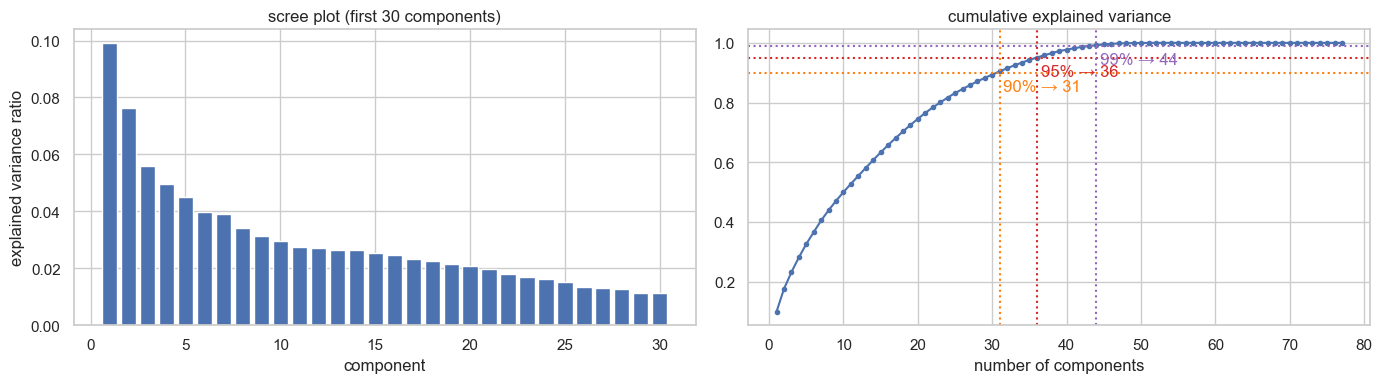

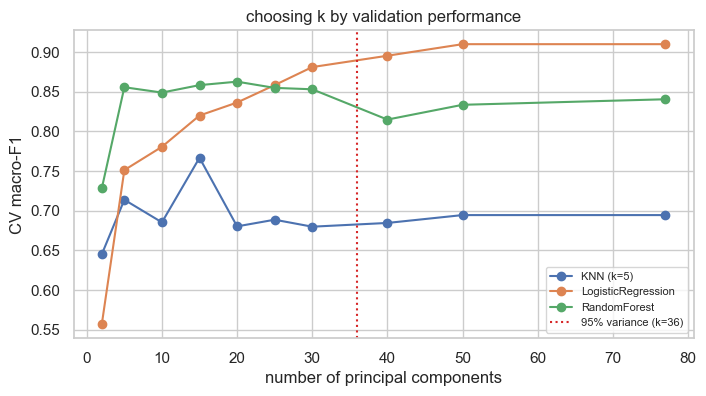

90% → 31, 95% → 36, 99% → 44 components (of 77); using k = 36


In [7]:
cum = np.cumsum(pca.explained_ratio_)
k90, k95, k99 = [int(np.searchsorted(cum, t) + 1) for t in (0.90, 0.95, 0.99)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, 31), pca.explained_ratio_[:30]); ax[0].set_title('scree plot (first 30 components)'); ax[0].set_xlabel('component'); ax[0].set_ylabel('explained variance ratio')
ax[1].plot(range(1, len(cum) + 1), cum, '.-')
for k, t, c in [(k90, 0.90, 'tab:orange'), (k95, 0.95, 'tab:red'), (k99, 0.99, 'tab:purple')]:
    ax[1].axhline(t, ls=':', c=c); ax[1].axvline(k, ls=':', c=c); ax[1].text(k + 0.5, t - 0.06, f'{int(t*100)}% → {k}', color=c)
ax[1].set_title('cumulative explained variance'); ax[1].set_xlabel('number of components')
plt.tight_layout(); savefig('q1_variance'); plt.show()

# accuracy-based check: CV macro-F1 as a function of k
ks = [2, 5, 10, 15, 20, 25, 30, 40, 50, len(cum)]
k_rows = []
for k in ks:
    Z = pca.transform(X_tr, k)
    for name, make in MODELS.items():
        f1s = [f1_score(y_tr[va], make().fit(Z[tr], y_tr[tr]).predict(Z[va]), average='macro') for tr, va in skf.split(Z, y_tr)]
        k_rows.append({'k': k, 'model': name, 'macro F1': np.mean(f1s)})
k_df = pd.DataFrame(k_rows)
plt.figure(figsize=(8, 4))
for name, g in k_df.groupby('model'):
    plt.plot(g['k'], g['macro F1'], 'o-', label=name)
plt.axvline(k95, ls=':', c='tab:red', label=f'95% variance (k={k95})')
plt.xlabel('number of principal components'); plt.ylabel('CV macro-F1'); plt.legend(fontsize=8); plt.title('choosing k by validation performance')
savefig('q1_k_selection'); plt.show()
K = k95
results['q1_pca'] = {'n_features': len(cum), 'k90': k90, 'k95': k95, 'k99': k99, 'chosen_k': K,
                     'top5_ratio': pca.explained_ratio_[:5].round(4).tolist(), 'sweeps': int(pca.sweeps_)}
results['q1_k_curve'] = k_df.round(4).to_dict('records')
print(f'90% → {k90}, 95% → {k95}, 99% → {k99} components (of {len(cum)}); using k = {K}')

### 5. The same classifiers on the PCA-reduced data

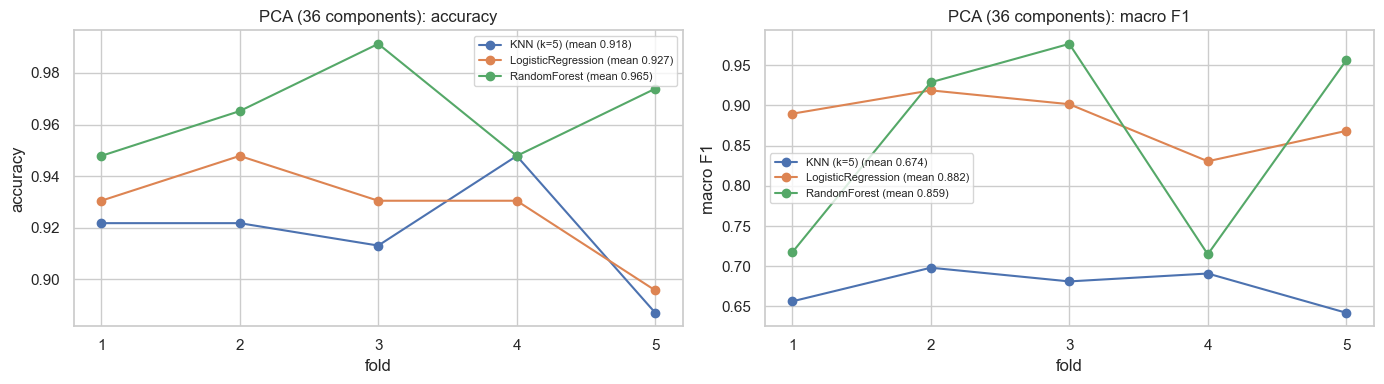

accuracy         macro F1        
                       mean     std     mean     std
model                                               
KNN (k=5)            0.9183  0.0218   0.6737  0.0237
LogisticRegression   0.9270  0.0191   0.8818  0.0340
RandomForest         0.9652  0.0184   0.8588  0.1314

In [8]:
Z_tr, Z_te = pca.transform(X_tr, K), pca.transform(X_te, K)
cv_pca = cv_scores(Z_tr, y_tr)
plot_cv(cv_pca, f'PCA ({K} components)', 'q1_cv_pca')
_agg = cv_pca.groupby('model')[['accuracy', 'macro F1']].agg(['mean', 'std']).round(4)
results['q1_cv_pca'] = {m: {f'{a} {b}': v for (a, b), v in row.items()} for m, row in _agg.iterrows()}
cv_pca.groupby('model')[['accuracy', 'macro F1']].agg(['mean', 'std']).round(4)

### 6. Test-set results before and after PCA

In [9]:
rows = []
for name, make in MODELS.items():
    for label, (A, B) in {'original': (X_tr, X_te), f'PCA k={K}': (Z_tr, Z_te)}.items():
        p = make().fit(A, y_tr).predict(B)
        rows.append({'model': name, 'features': label, 'accuracy': accuracy_score(y_te, p),
                     'balanced acc.': balanced_accuracy_score(y_te, p), 'macro F1': f1_score(y_te, p, average='macro')})
test_tbl = pd.DataFrame(rows).set_index(['model', 'features'])
results['q1_test'] = {f'{m} | {f}': v for (m, f), v in test_tbl.round(4).to_dict('index').items()}
test_tbl.round(4)

accuracy  balanced acc.  macro F1
model              features                                   
LogisticRegression original    0.9646         0.9249    0.9113
                   PCA k=36    0.9293         0.9156    0.8402
KNN (k=5)          original    0.9325         0.7109    0.6993
                   PCA k=36    0.9196         0.6924    0.6865
RandomForest       original    0.9904         0.9132    0.9483
                   PCA k=36    0.9646         0.8291    0.8853

### 7. Did the distribution change?

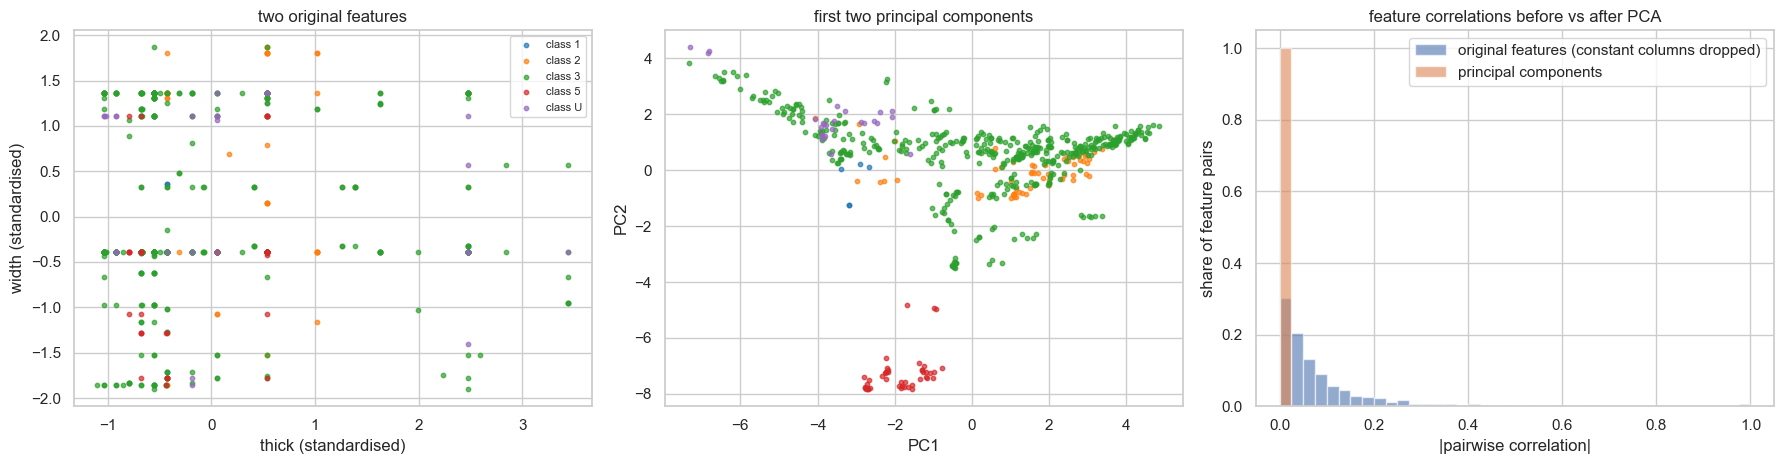

{'mean_abs_corr_before': 0.09255297835490402, 'max_abs_corr_after': 1.2445454193570952e-14, 'var_before_total': 77.13414634146346, 'var_after_total': 73.34437814214662}


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
pal = dict(zip(CLASSES, sns.color_palette('tab10', len(CLASSES))))
for c in CLASSES:
    m = y_tr == c
    ax[0].scatter(X_tr[m, FEATURES.index('thick')], X_tr[m, FEATURES.index('width')], s=10, color=pal[c], label=f'class {c}', alpha=0.7)
    ax[1].scatter(Z_tr[m, 0], Z_tr[m, 1], s=10, color=pal[c], label=f'class {c}', alpha=0.7)
ax[0].set_xlabel('thick (standardised)'); ax[0].set_ylabel('width (standardised)'); ax[0].set_title('two original features'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); ax[1].set_title('first two principal components')
corr_before = np.abs(np.corrcoef(X_tr.T)[np.triu_indices(X_tr.shape[1], 1)])
corr_after = np.abs(np.corrcoef(Z_tr.T)[np.triu_indices(K, 1)])
bins = np.linspace(0, 1, 41)  # shared bins: PC correlations are ~1e-15, auto-binning would give them hairline bins
for vals, label in [(corr_before[~np.isnan(corr_before)], 'original features (constant columns dropped)'), (corr_after, 'principal components')]:
    ax[2].hist(vals, bins=bins, alpha=0.6, weights=np.full(len(vals), 1 / len(vals)), label=label)
ax[2].set_xlabel('|pairwise correlation|'); ax[2].set_ylabel('share of feature pairs')
ax[2].set_title('feature correlations before vs after PCA'); ax[2].legend()
plt.tight_layout(); savefig('q1_distribution'); plt.show()
results['q1_corr'] = {'mean_abs_corr_before': float(np.nanmean(corr_before)), 'max_abs_corr_after': float(corr_after.max()),
                      'var_before_total': float(X_tr.var(0, ddof=1).sum()), 'var_after_total': float(Z_tr.var(0, ddof=1).sum())}
print(results['q1_corr'])

# Question 2 — Linear Discriminant Analysis

### 1. LDA from scratch
- **(a)** Within-class scatter $S_W = \sum_c \sum_{x\in c}(x-\mu_c)(x-\mu_c)^\top$ and between-class scatter $S_B = \sum_c n_c(\mu_c-\mu)(\mu_c-\mu)^\top$.
- The discriminants are the leading eigenvectors of $S_W^{-1}S_B$. With one-hot features, $S_W$ is singular (dummy columns sum to one), so a small ridge $\lambda I$ is added before inverting. The problem is solved in its symmetric form, using $S_W^{-1/2}$, so that the Jacobi solver from Q1 can be reused.
- **(b)** At most C − 1 = 4 discriminants exist. The number kept is the smallest k whose eigenvalues cover the requested share of the total discriminant "variance" (between/within ratio).

In [11]:
def scatter_matrices(X, y):
    mu = X.mean(0)
    d = X.shape[1]
    Sw, Sb = np.zeros((d, d)), np.zeros((d, d))
    for c in np.unique(y):
        Xc = X[y == c]
        mc = Xc.mean(0)
        Sw += (Xc - mc).T @ (Xc - mc)
        diff = (mc - mu)[:, None]
        Sb += len(Xc) * diff @ diff.T
    return Sw, Sb

class LDAScratch:
    def __init__(self, variance_to_keep=0.95, ridge=1e-3):
        self.variance_to_keep, self.ridge = variance_to_keep, ridge

    def fit(self, X, y):
        Sw, Sb = scatter_matrices(X, y)
        Sw = Sw + self.ridge * np.trace(Sw) / len(Sw) * np.eye(len(Sw))
        w, U, _ = Singular_Value_Decomp(Sw)                      # Sw = U diag(w) U^T
        Sw_inv_sqrt = U @ np.diag(1 / np.sqrt(w)) @ U.T
        M = Sw_inv_sqrt @ Sb @ Sw_inv_sqrt                        # symmetric, same eigenvalues as Sw^-1 Sb
        lam, E, _ = Singular_Value_Decomp(M)
        n_max = len(np.unique(y)) - 1
        self.eigvals_ = lam[:n_max]
        self.ratio_ = self.eigvals_ / self.eigvals_.sum()
        self.n_components_ = self.select_components(self.variance_to_keep)
        self.scalings_ = Sw_inv_sqrt @ E[:, :n_max]               # back to the original feature space
        return self

    def select_components(self, share):
        return int(np.searchsorted(np.cumsum(self.ratio_), share - 1e-12) + 1)

    def transform(self, X, k=None):
        return X @ self.scalings_[:, :(k or self.n_components_)]

lda = LDAScratch(0.95).fit(X_tr, y_tr)
print('discriminant eigenvalues:', lda.eigvals_.round(3))
print('share of discriminant variance:', lda.ratio_.round(4))
for share in (0.80, 0.90, 0.95, 0.99):
    print(f'  keep {share:.0%} → {lda.select_components(share)} discriminant(s)')
results['q2_lda'] = {'eigvals': lda.eigvals_.round(4).tolist(), 'ratio': lda.ratio_.round(4).tolist(),
                     'n_components_95': lda.n_components_,
                     'auto': {str(s): lda.select_components(s) for s in (0.80, 0.90, 0.95, 0.99)}}

discriminant eigenvalues: [1.586834e+03 1.528600e+01 7.809000e+00 1.257000e+00]
share of discriminant variance: [9.849e-01 9.500e-03 4.800e-03 8.000e-04]
  keep 80% → 1 discriminant(s)
  keep 90% → 1 discriminant(s)
  keep 95% → 1 discriminant(s)
  keep 99% → 2 discriminant(s)


### 2–3. PCA vs LDA: which features matter, and how the sample space looks

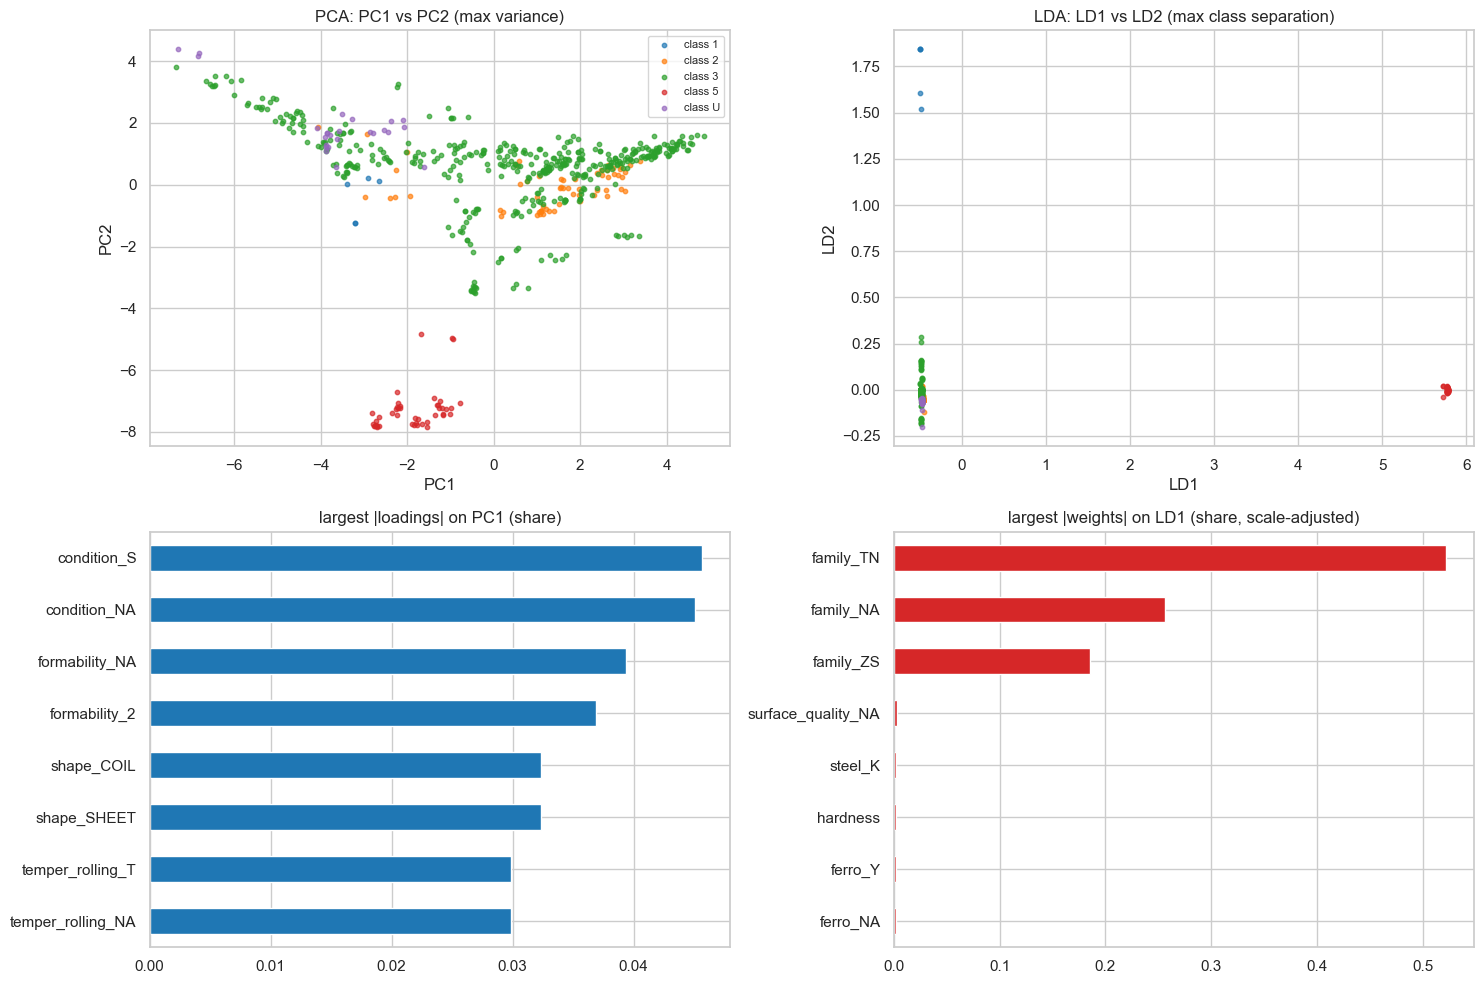

,PC1 feature,PC1 share,LD1 feature,LD1 share
0,condition_S,0.046,family_TN,0.522
1,condition_NA,0.045,family_NA,0.256
2,formability_NA,0.039,family_ZS,0.186
3,formability_2,0.037,surface_quality_NA,0.003
4,shape_COIL,0.032,steel_K,0.002
5,shape_SHEET,0.032,hardness,0.002
6,temper_rolling_T,0.030,ferro_Y,0.002
7,temper_rolling_NA,0.030,ferro_NA,0.002


In [12]:
L_tr, L_te = lda.transform(X_tr, 4), lda.transform(X_te, 4)
def top_features(weights, n=8):
    s = pd.Series(np.abs(weights) / np.abs(weights).sum(), index=FEATURES)
    return s.sort_values(ascending=False).head(n)

top_pc1, top_ld1 = top_features(pca.components_[:, 0]), top_features(lda.scalings_[:, 0] * X_tr.std(0))
results['q2_top_pc1'] = top_pc1.round(4).to_dict(); results['q2_top_ld1'] = top_ld1.round(4).to_dict()

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
for c in CLASSES:
    m = y_tr == c
    ax[0, 0].scatter(Z_tr[m, 0], Z_tr[m, 1], s=10, color=pal[c], label=f'class {c}', alpha=0.7)
    ax[0, 1].scatter(L_tr[m, 0], L_tr[m, 1], s=10, color=pal[c], label=f'class {c}', alpha=0.7)
ax[0, 0].set_title('PCA: PC1 vs PC2 (max variance)'); ax[0, 0].set_xlabel('PC1'); ax[0, 0].set_ylabel('PC2'); ax[0, 0].legend(fontsize=8)
ax[0, 1].set_title('LDA: LD1 vs LD2 (max class separation)'); ax[0, 1].set_xlabel('LD1'); ax[0, 1].set_ylabel('LD2')
top_pc1[::-1].plot.barh(ax=ax[1, 0], color='tab:blue'); ax[1, 0].set_title('largest |loadings| on PC1 (share)')
top_ld1[::-1].plot.barh(ax=ax[1, 1], color='tab:red'); ax[1, 1].set_title('largest |weights| on LD1 (share, scale-adjusted)')
plt.tight_layout(); savefig('q2_pca_vs_lda'); plt.show()
pd.DataFrame({'PC1 feature': top_pc1.index, 'PC1 share': top_pc1.values.round(3), 'LD1 feature': top_ld1.index, 'LD1 share': top_ld1.values.round(3)})

### 4. 2 × 2 table: feature extraction × classifier (test accuracy)
To compare like with like, both methods reduce to the **same dimension, 4** (the maximum LDA allows for 5 classes). Two classifiers: **KNN** (purely distance-based) and **logistic regression** (linear).

In [13]:
Z4_tr, Z4_te = pca.transform(X_tr, 4), pca.transform(X_te, 4)
CLFS = {'KNN (k=5)': lambda: KNeighborsClassifier(5), 'LogisticRegression': lambda: LogisticRegression(max_iter=3000, class_weight='balanced')}
table, table_f1 = {}, {}
for fe, (A, B) in {'PCA (4 PCs)': (Z4_tr, Z4_te), 'LDA (4 LDs)': (L_tr, L_te)}.items():
    table[fe], table_f1[fe] = {}, {}
    for cn, make in CLFS.items():
        p = make().fit(A, y_tr).predict(B)
        table[fe][cn] = accuracy_score(y_te, p); table_f1[fe][cn] = f1_score(y_te, p, average='macro')
table = pd.DataFrame(table).T; table_f1 = pd.DataFrame(table_f1).T
results['q2_table_acc'] = table.round(4).to_dict('index'); results['q2_table_f1'] = table_f1.round(4).to_dict('index')
print('test accuracy'); print(table.round(4)); print('\ntest macro-F1'); print(table_f1.round(4))

test accuracy
             KNN (k=5)  LogisticRegression
PCA (4 PCs)     0.9421              0.7974
LDA (4 LDs)     0.9936              0.9293

test macro-F1
             KNN (k=5)  LogisticRegression
PCA (4 PCs)     0.7203              0.6534
LDA (4 LDs)     0.9518              0.8697


### 5. LDA as a classifier: 5-fold CV with ROC curves and AUC computed from scratch
The LDA classifier (sklearn's `LinearDiscriminantAnalysis`, using the shrinkage solver because $S_W$ is singular) provides class probabilities. With 5 classes, ROC is computed **one-vs-rest**: for each class, sweep the threshold over its probability scores, count TPR/FPR at each step, and integrate with the trapezoidal rule. Each fold reports the per-class AUC, the **macro** average and a **micro**-averaged curve (all one-vs-rest decisions pooled).

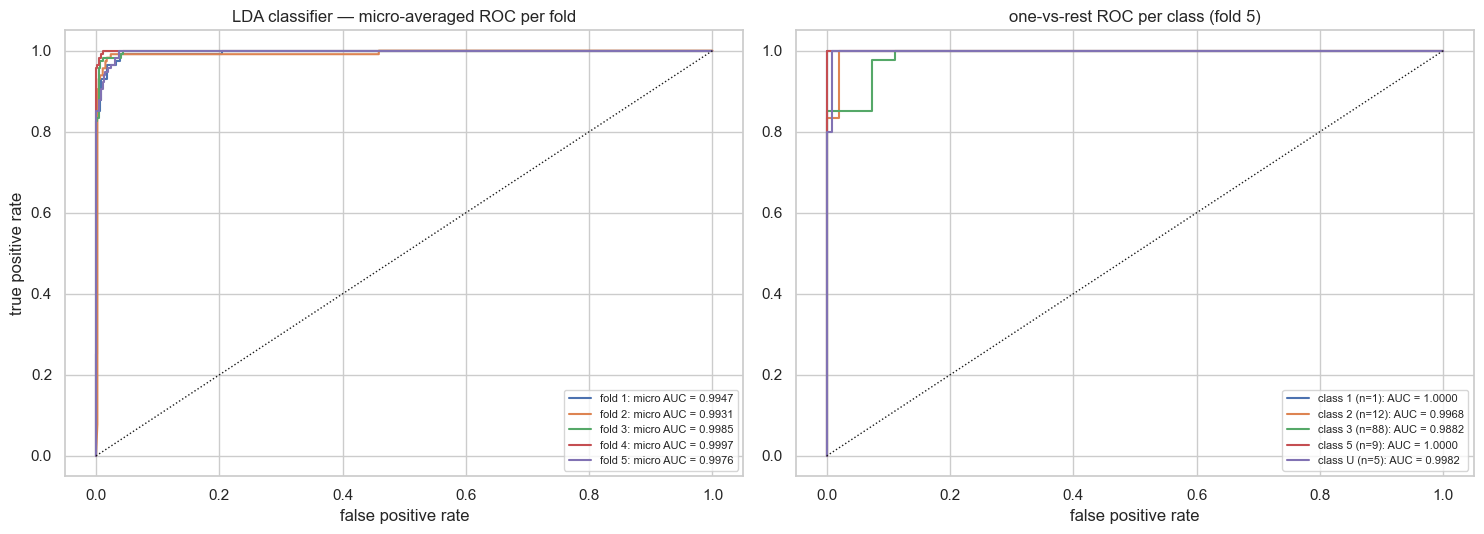

sanity check, fold 5 micro AUC: scratch 0.997561 vs sklearn 0.997561


,accuracy,micro AUC,macro AUC,AUC class 1,AUC class 2,AUC class 3,AUC class 5,AUC class U
fold,,,,,,,,
1,0.9304,0.9947,0.9648,1.0000,0.9977,0.9610,1.0,0.8655
2,0.9565,0.9931,0.9974,0.9956,1.0000,0.9914,1.0,1.0000
3,0.9739,0.9985,0.9979,1.0000,1.0000,0.9966,1.0,0.9927
4,0.9826,0.9997,1.0000,1.0000,1.0000,1.0000,1.0,1.0000
5,0.9391,0.9976,0.9966,1.0000,0.9968,0.9882,1.0,0.9982


In [14]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

def roc_curve_scratch(y_true, scores):
    order = np.argsort(-scores, kind='mergesort')
    y, s = y_true[order], scores[order]
    distinct = np.r_[np.nonzero(np.diff(s))[0], len(s) - 1]       # last index of each tied score block
    tps = np.cumsum(y)[distinct]
    fps = (distinct + 1) - tps
    P, N = y.sum(), len(y) - y.sum()
    tpr = np.r_[0, tps / P]; fpr = np.r_[0, fps / N]
    return fpr, tpr

def auc_scratch(fpr, tpr):
    return float(np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2))

fold_rows = []
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for fold, (tr, va) in enumerate(skf.split(X_tr, y_tr), 1):
    clf = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto').fit(X_tr[tr], y_tr[tr])
    P = clf.predict_proba(X_tr[va])
    Y = (y_tr[va][:, None] == clf.classes_[None, :]).astype(int)
    per_class = {}
    for k, c in enumerate(clf.classes_):
        if 0 < Y[:, k].sum() < len(Y):
            per_class[c] = auc_scratch(*roc_curve_scratch(Y[:, k], P[:, k]))
    fpr_m, tpr_m = roc_curve_scratch(Y.ravel(), P.ravel())
    micro = auc_scratch(fpr_m, tpr_m)
    ax[0].plot(fpr_m, tpr_m, label=f'fold {fold}: micro AUC = {micro:.4f}')
    fold_rows.append({'fold': fold, 'accuracy': np.mean(clf.predict(X_tr[va]) == y_tr[va]), 'micro AUC': micro,
                      'macro AUC': np.mean(list(per_class.values())), **{f'AUC class {c}': v for c, v in per_class.items()}})
ax[0].plot([0, 1], [0, 1], 'k:', lw=1); ax[0].set_xlabel('false positive rate'); ax[0].set_ylabel('true positive rate')
ax[0].set_title('LDA classifier — micro-averaged ROC per fold'); ax[0].legend(fontsize=8)
# per-class curves on the last fold, for detail
for k, c in enumerate(clf.classes_):
    if 0 < Y[:, k].sum() < len(Y):
        f, t = roc_curve_scratch(Y[:, k], P[:, k]); ax[1].plot(f, t, label=f'class {c} (n={Y[:, k].sum()}): AUC = {auc_scratch(f, t):.4f}')
ax[1].plot([0, 1], [0, 1], 'k:', lw=1); ax[1].set_xlabel('false positive rate'); ax[1].set_title('one-vs-rest ROC per class (fold 5)'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('q2_roc'); plt.show()

from sklearn.metrics import roc_auc_score
check = roc_auc_score(Y.ravel(), P.ravel())
roc_df = pd.DataFrame(fold_rows).set_index('fold')
results['q2_roc'] = roc_df.round(4).to_dict('index'); results['q2_roc_mean'] = roc_df.mean().round(4).to_dict()
print(f'sanity check, fold 5 micro AUC: scratch {fold_rows[-1]["micro AUC"]:.6f} vs sklearn {check:.6f}')
roc_df.round(4)

In [15]:
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)